# plot_01a. ERA5: distributions and plumes (figures)

The first of four notebooks drawing what calc_03a to calc_03c saved, so nothing slow runs: plot_01a the distributions and plumes, plot_01b the tests at the point, plot_01c the maps and plot_01d the observed change. The section numbers run across plot_01a to plot_01c.

Here: ERA5's climatology and each model's bias (*First Look*), then at the point the distributions of the raw values and anomalies (section 2) and the ensemble plume through time (section 3).

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

from plotting_modules import formatting
from plotting_modules.constants import SEASONS
from extant import era5_evaluation as ev
from extant.config import VARIABLES
from extant.datatree import tree_to_dataset
from extant.logger import setup_logging
from extant.plots import antarctica, charts, era5_evaluation as evp, forced_response as fr

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

In [3]:
#(t): As in calc_03a and calc_03b: the variable (its name and units), and the grid point and its label
VARIABLE = VARIABLES['tas']
SAMPLE_LAT_LON = dict(lat=-82.5, lon=120.0)
POINT_LABEL = formatting.format_latlon(SAMPLE_LAT_LON)

#(t): The model of the one-model figures
EXAMPLE_MODEL = 'CanESM5'

In [4]:
#(t): Where calc_03a to calc_03c saved their results: JASMIN's scratch
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SCRATCH_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt')

## Which Results

Run **one** of the next two sections: each sets the folder the results are opened from, the sample's or the full data's.

### Sample data

In [5]:
#(t): The sample's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

In [6]:
#(t): The full data's results
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

## Open the Results

First what calc_03a to calc_03c saved in `RESULTS_DIR`, then each result opened.

In [7]:
#(t): What calc_03a to calc_03c saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full'),
 ['anomaly_ranks.zarr',
  'demo_anomaly_ranks.zarr',
  'demo_detrended_ranks.zarr',
  'demo_plume.zarr',
  'demo_statistics.zarr',
  'demo_tests.zarr',
  'detections.zarr',
  'detrended_ranks.zarr',
  'era5_kurtosis.zarr',
  'era5_lower_tail.zarr',
  'era5_mean.zarr',
  'era5_point.zarr',
  'era5_regional.zarr',
  'era5_regional_trend.zarr',
  'era5_skewness.zarr',
  'era5_std.zarr',
  'era5_trend.zarr',
  'era5_upper_tail.zarr',
  'era5_width.zarr',
  'eval_map_table.zarr',
  'eval_table.zarr',
  'experiment_noise.zarr',
  'final_mean.zarr',
  'final_quantiles.zarr',
  'first_look.zarr',
  'forced.zarr',
  'hist_nat_final_quantiles.zarr',
  'histnat_point.zarr',
  'historical_kurtosis.zarr',
  'historical_lower_tail.zarr',
  'historical_mean.zarr',
  'historical_point.zarr',
  'historical_skewness.zarr',
  'historical_std.zarr',
  'historical_trend.zarr',
  'historical_upper_tail.zarr',
  'historical_width.zarr',
  'mean_

In [8]:
#(t): ERA5's 1979-2013 mean in every season, and each model's ensemble mean minus it
first_look_ds = xr.open_zarr(RESULTS_DIR / 'first_look.zarr').load()

In [9]:
#(t): At the point: each model's historical members, /<model>/historical
historical_point_tree = xr.open_datatree(RESULTS_DIR / 'historical_point.zarr', engine='zarr').load()

In [10]:
#(t): ... their hist-nat members, /<model>/hist-nat
histnat_point_tree = xr.open_datatree(RESULTS_DIR / 'histnat_point.zarr', engine='zarr').load()

In [11]:
#(t): ... and ERA5
era5_point_da = xr.open_zarr(RESULTS_DIR / 'era5_point.zarr')['tas'].load()

In [ ]:
#(t): Every statistic notebook calc_03a saved, in one store, each a variable named after it: every member's in
#(t): /<model>/historical (on member, season, lat, lon), ERA5's in /ERA5 (on season, lat, lon)
statistics_path = RESULTS_DIR / 'statistics.zarr'
statistics_path

In [ ]:
statistics_tree = xr.open_datatree(statistics_path, engine='zarr').load()

In [ ]:
#(t): The models' members, /<model>/historical
historical_statistics_tree = statistics_tree.match('*/historical')

In [ ]:
#(t): ... and ERA5's
era5_statistics_ds = statistics_tree['ERA5'].to_dataset().load()

## The Moment Test at the Point

Where ERA5's mean and standard deviation fall among each model's members at `SAMPLE_LAT_LON` (`ev.locate`, gone through step by step in notebook plot_01b), for the ✓ and ✗ in section 2's KDE panels. The same cells as plot_01b's *Every model at the point*.

In [ ]:
#(t): ERA5's eight at the point, along a statistic dim
era5_point_statistics_da = era5_statistics_ds.sel(SAMPLE_LAT_LON).to_dataarray('statistic')
era5_point_statistics_da

In [ ]:
#(t): Where ERA5's value of each statistic falls among each model's members at the point, all eight at once:
#(t): to_dataarray puts a model's eight variables along a statistic dim, in the same order as ERA5's,
#(t): /<model>/historical, on (statistic, member, season)
point_test_tree = xr.DataTree.from_dict({
    node.path: ev.locate(node.to_dataset().sel(SAMPLE_LAT_LON).to_dataarray('statistic'), era5_point_statistics_da)
    for node in historical_statistics_tree.leaves
})

In [ ]:
#(t): The moment test: each model's four
moment_statistics = ['mean', 'std', 'skewness', 'kurtosis']
moment_test_tree = point_test_tree.sel(statistic=moment_statistics)

In [52]:
#(t): With the values each moment was worked out on, for the figures' labels
moment_test_tree = xr.DataTree.from_dict({
    node.path: node.to_dataset().assign_coords(treatment=('statistic', ['raw', 'detrended', 'detrended', 'detrended']))
    for node in moment_test_tree.leaves
})
moment_test_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:     (statistic: 4, season: 4, member: 65)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -30.53 ... -0.4231
│               lower       (statistic, season) float64 128B -31.0 -58.55 ... -0.9818 -1.007
│               median      (statistic, season) float64 128B -30.53 -58.08 ... -0.3695
│               upper       (statistic, season) float64 128B -30.12 -57.55 ... 1.034 0.6424
│               percentile  (statistic, season) float64 128B 0.0 100.0 100.0 ... 70.77 30.77
│               pvalue      (statistic, season) float64 128B 0.0303 0.0303 ... 0.6061 0.6364
│               verdict     (statistic, season) float64 128B -1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:     (statistic: 4, season: 4, member: 63)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 504B 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p5f1'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 8kB -273.1 -273.1 ... nan
│               lower       (statistic, season) float64 128B -273.1 -273.1 ... -1.125
│               median      (statistic, season) float64 128B -33.27 -60.47 ... -0.235
│               upper       (statistic, season) float64 128B -32.26 -59.65 ... 1.771 1.849
│               percentile  (statistic, season) float64 128B 63.49 100.0 ... 53.33 37.78
│               pvalue      (statistic, season) float64 128B 0.75 0.03125 ... 0.9565 0.7826
│               verdict     (statistic, season) float64 128B 0.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
│               testable    (statistic, season) float64 128B 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensions:     (statistic: 4, season: 4, member: 55)
│           Coordinates:
│               lon         float64 8B 120.0
│             * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│               lat         float64 8B -82.5
│             * member      (member) object 440B 'r11i1p1f3' 'r12i1p1f3' ... 'r60i1p1f3'
│             * statistic   (statistic) <U8 128B 'mean' 'std' 'skewness' 'kurtosis'
│               treatment   (statistic) <U9 144B 'raw' 'detrended' 'detrended' 'detrended'
│           Data variables:
│               era5        (statistic, season) float64 128B -32.97 -54.47 ... -0.5614
│               members     (statistic, member, season) float64 7kB -28.02 -56.41 ... 0.1943
│               lower       (statistic, season) float64 128B -28.02 -56.54 ... -0.9203
│               median      (statistic, season) float64 128B -27.71 -56.09 ... -0.3381
│               upper       (statistic, season) float64 128B -27.32 -55.54 ... 0.9406 0.96
│               percentile  (statistic, season) float64 128B 0.0 100.0 100.0 ... 61.

## First Look

ERA5's 1979–2013 mean in every season, and each model's historical ensemble mean minus it: the mean-state bias, which only the tests of raw values see.

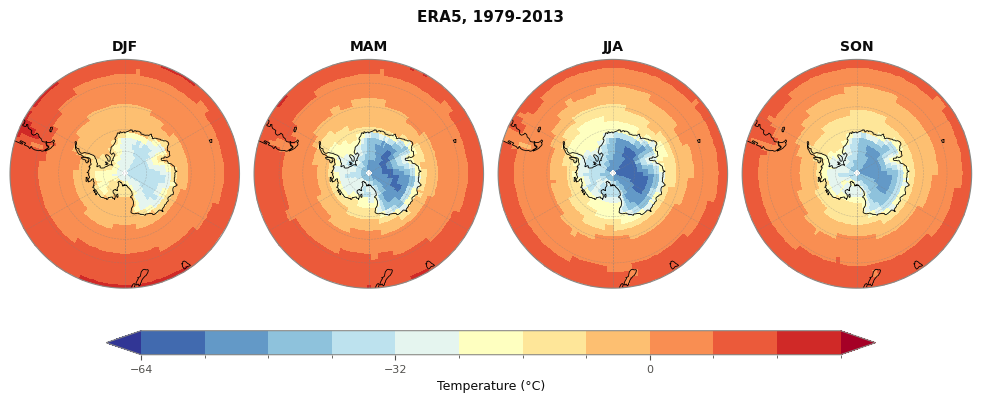

In [37]:
#(t): ERA5's mean temperature in every season (columns), 1979-2013, on its own range in about 14 round steps
#(t): (MaxNLocator), with every fourth labelled
era5_climatology_da = first_look_ds['era5_mean'].sel(season=SEASONS)
levels = MaxNLocator(14).tick_values(float(era5_climatology_da.min()), float(era5_climatology_da.max()))
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=1, n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=1, n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(era5_climatology_da, None, 'season', axes=axes, cax=cax, levels=levels,
                                  cmap='RdYlBu_r', ticks=levels[::4], label=f'Temperature ({VARIABLE.units})')
antarctica.label_columns(axes, SEASONS)
fig.suptitle('ERA5, 1979-2013');

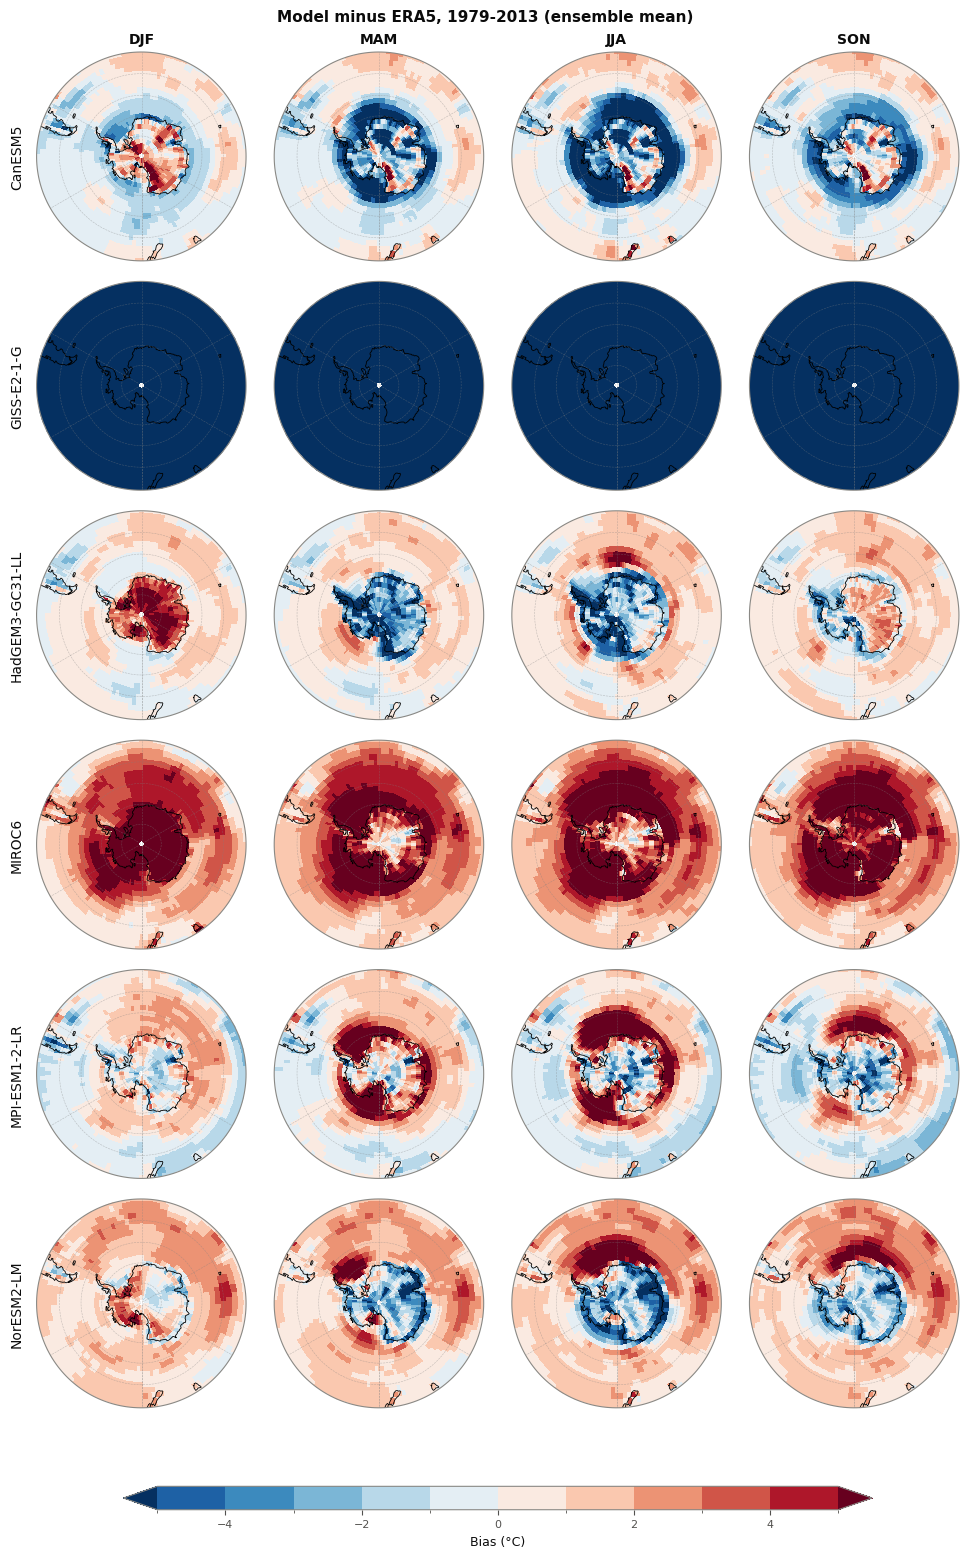

In [38]:
#(t): Each model's (rows) ensemble-mean bias against ERA5, every season (columns)
model_bias_da = first_look_ds['model_bias'].sel(season=SEASONS)
models = model_bias_da['model'].values
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=len(models), n_cols=len(SEASONS), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=len(models), n_cols=len(SEASONS))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(model_bias_da, 'model', 'season', axes=axes, cax=cax,
                                  levels=np.linspace(-5, 5, 11), cmap='RdBu_r', label=f'Bias ({VARIABLE.units})')
antarctica.label_columns(axes, SEASONS)
antarctica.label_rows(axes, models)
fig.suptitle('Model minus ERA5, 1979-2013 (ensemble mean)');

## 2. Distributions: Raw Values and Anomalies

For each season: each member's KDE (thin), the pooled ensemble (thick blue) and ERA5's (black), with ERA5's values as a rug; the ✓/✗ is the moment test of the mean (raw values) or of the standard deviation (anomalies). The Q–Q panel: the members' quantiles against ERA5's; on the 1:1 line the distributions match. ERA5 and every member share one kernel bandwidth, so differences come from the data rather than the smoothing.

In [60]:
#(t): EXAMPLE_MODEL's members and ERA5 at the point
eval_members_da = historical_point_tree[EXAMPLE_MODEL]['historical']['tas']
eval_era5_da = era5_point_da
eval_era5_da

<xarray.DataArray 'tas' (year: 35, season: 4)> Size: 560B
-32.97 -55.57 -51.88 -45.79 -33.46 -53.79 ... -46.57 -33.87 -50.94 -51.86 -43.27
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year     (year) int64 280B 1979 1980 1981 1982 1983 ... 2010 2011 2012 2013
    lon      float64 8B 120.0
    lat      float64 8B -82.5

In [61]:
#(t): Their KDEs and quantiles, for the figure (ev.distribution_summary): raw values, anomalies, detrended
eval_distributions = ev.distribution_summary(eval_members_da, eval_era5_da, ('raw', 'anomaly', 'detrended'))
eval_distributions['anomaly']

<xarray.Dataset> Size: 1MB
Dimensions:           (season: 4, year: 35, x: 600, member: 65, quantile: 19)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
    lon               float64 8B 120.0
    lat               float64 8B -82.5
  * x                 (x) float64 5kB -8.516 -8.487 -8.458 ... 8.76 8.789 8.818
  * member            (member) object 520B 'r10i1p1f1' ... 'r9i1p2f1'
  * quantile          (quantile) float64 152B 0.05 0.1 0.15 ... 0.85 0.9 0.95
Data variables:
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    member_kde        (x, member, season) float64 1MB 3.013e-37 ... 1.269e-22
    ensemble_kde      (x, season) float64 19kB 1.645e-26 7.982e-08 ... 1.997e-14
    obs_kde           (x, season) float64 19kB 1.169e-34 1.706e-10 ... 5.094e-20
    member_quantiles  (quantile, member, season) float64 40kB -1.211 ... 1.625
    obs_quantiles     (quantile, season) float64 608B -1.5 -2.214 ... 1.741
    bandwidth         (season) float64 32B 0.5148 0.7834 0.707 0.6275
Attributes: (1)

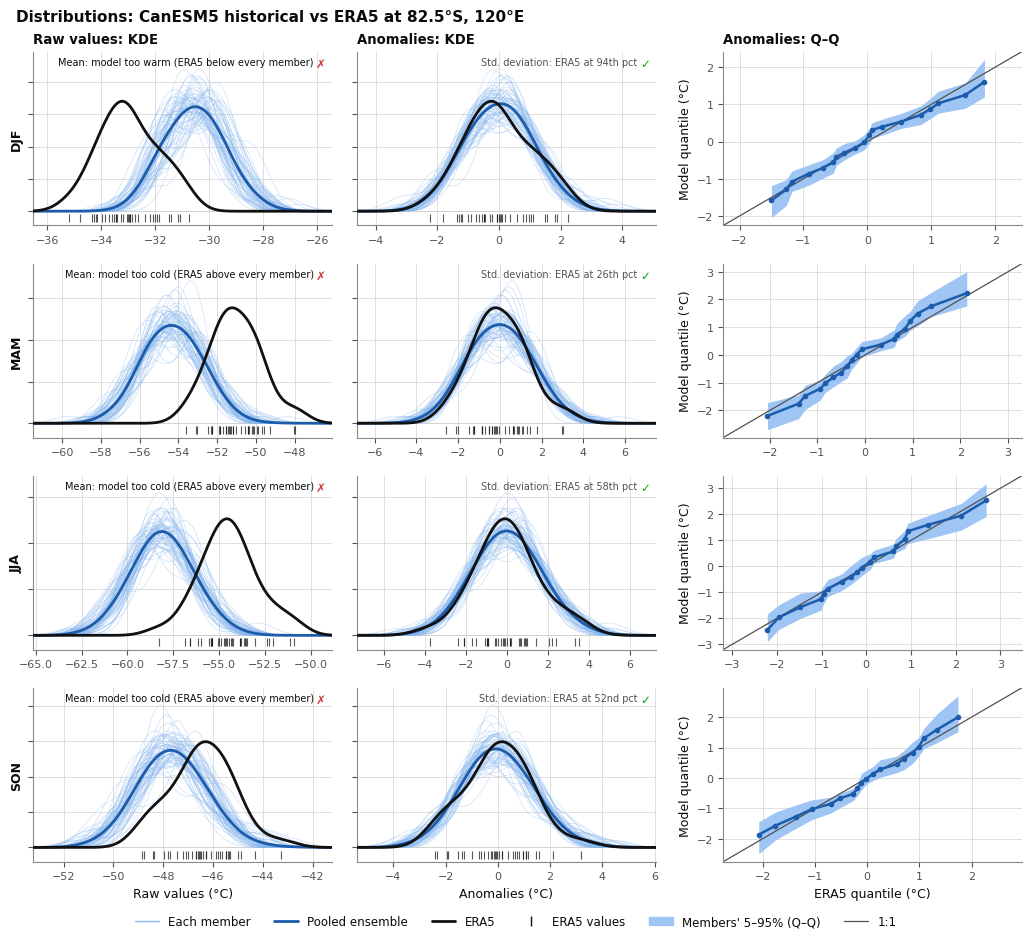

In [62]:
#(t): One model, every season (rows): the raw values' KDEs, the anomalies' KDEs and the anomalies' Q-Q plot, each KDE
#(t): panel with its moment test (the mean on raw values, the standard deviation on anomalies: evp.KDE_STATISTIC)
model_moments_ds = moment_test_tree[EXAMPLE_MODEL]['historical'].to_dataset()
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=3, n_legends=1, panel_height=1.5),
                 layout='constrained')
axes = fig.add_gridspec(len(SEASONS), 3).subplots(squeeze=False)
for i, season in enumerate(SEASONS):
    evp.plot_kde(eval_distributions['raw'].sel(season=season), ax=axes[i, 0])
    evp.plot_kde(eval_distributions['anomaly'].sel(season=season), ax=axes[i, 1])
    evp.plot_qq(eval_distributions['anomaly'].sel(season=season), ax=axes[i, 2])
    for ax, treatment in zip(axes[i, :2], ['raw', 'anomaly']):
        ok, message = evp.verdict(model_moments_ds.sel(season=season), evp.KDE_STATISTIC[treatment])
        evp.status_line(ax, 0.98, 0.97, ok, message, ha='right', fontsize=7)
        ax.tick_params(axis='y', labelleft=False)
    axes[i, 0].set_ylabel(season, fontweight='bold')
    axes[i, 2].set_ylabel(f'Model quantile ({VARIABLE.units})')

axes[0, 0].set_title(f"{ev.TREATMENTS['raw']}: KDE", loc='left')
axes[0, 1].set_title(f"{ev.TREATMENTS['anomaly']}: KDE", loc='left')
axes[0, 2].set_title(f"{ev.TREATMENTS['anomaly']}: Q–Q", loc='left')
axes[-1, 0].set_xlabel(f"{ev.TREATMENTS['raw']} ({VARIABLE.units})")
axes[-1, 1].set_xlabel(f"{ev.TREATMENTS['anomaly']} ({VARIABLE.units})")
axes[-1, 2].set_xlabel(f'ERA5 quantile ({VARIABLE.units})')
fig.legend(handles=evp.distribution_legend_handles(), loc='outside lower center', ncols=6, frameon=False)
fig.suptitle(f'Distributions: {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

In [63]:
#(t): Every model's (raw values and anomalies), by model
all_distributions = {node.parent.name: ev.distribution_summary(node['tas'], era5_point_da, ('raw', 'anomaly'))
                     for node in historical_point_tree.leaves}

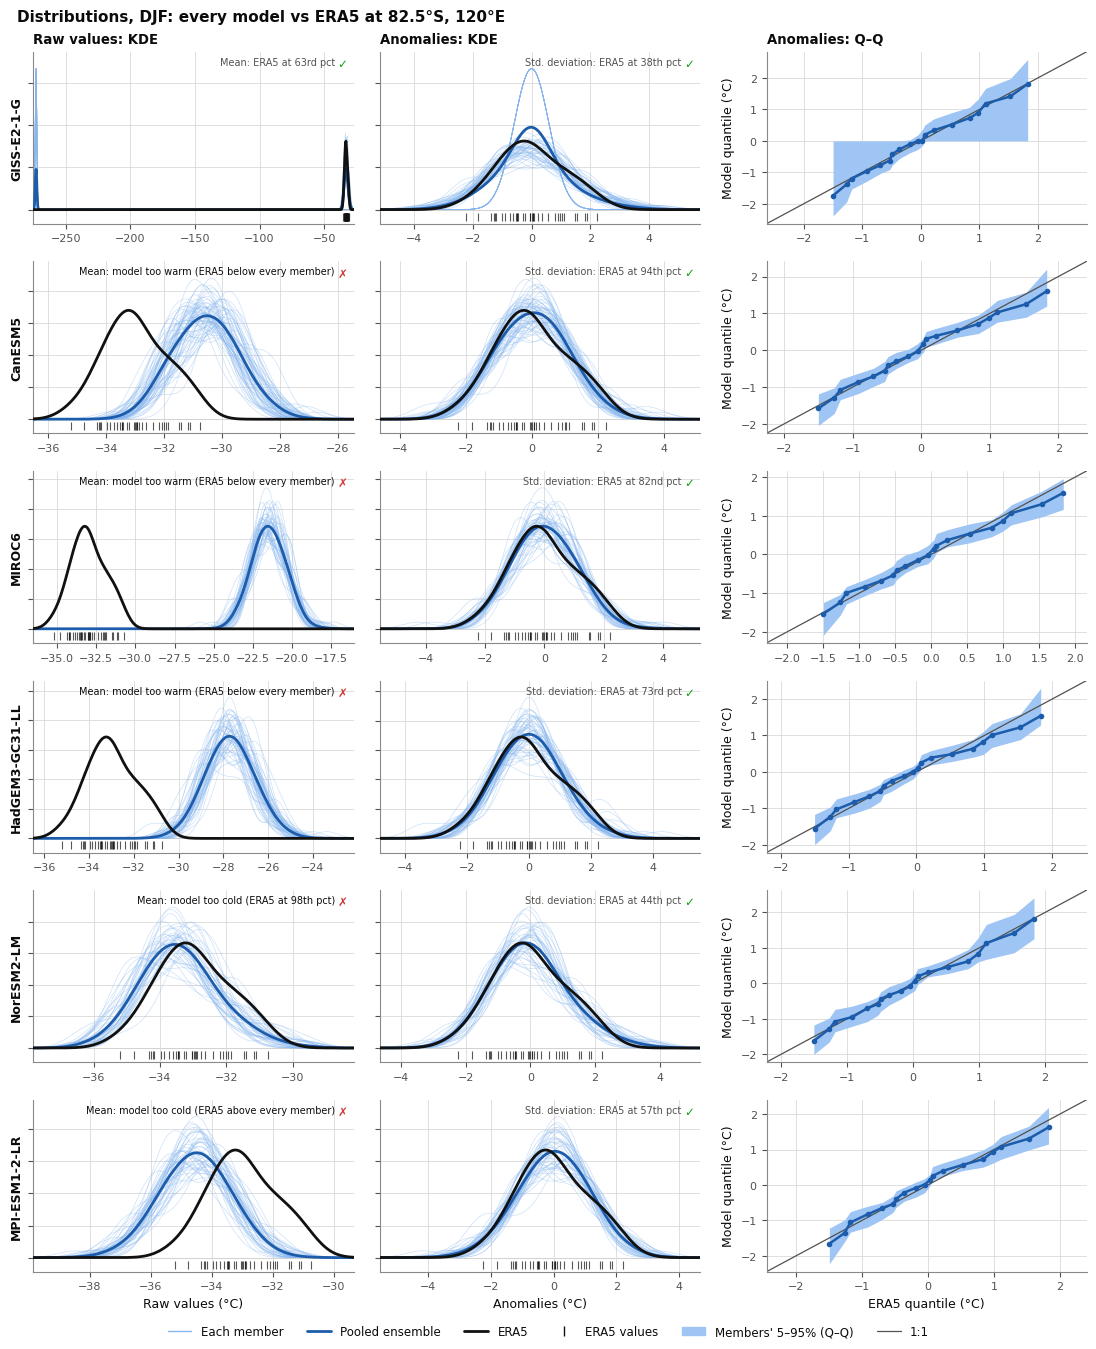

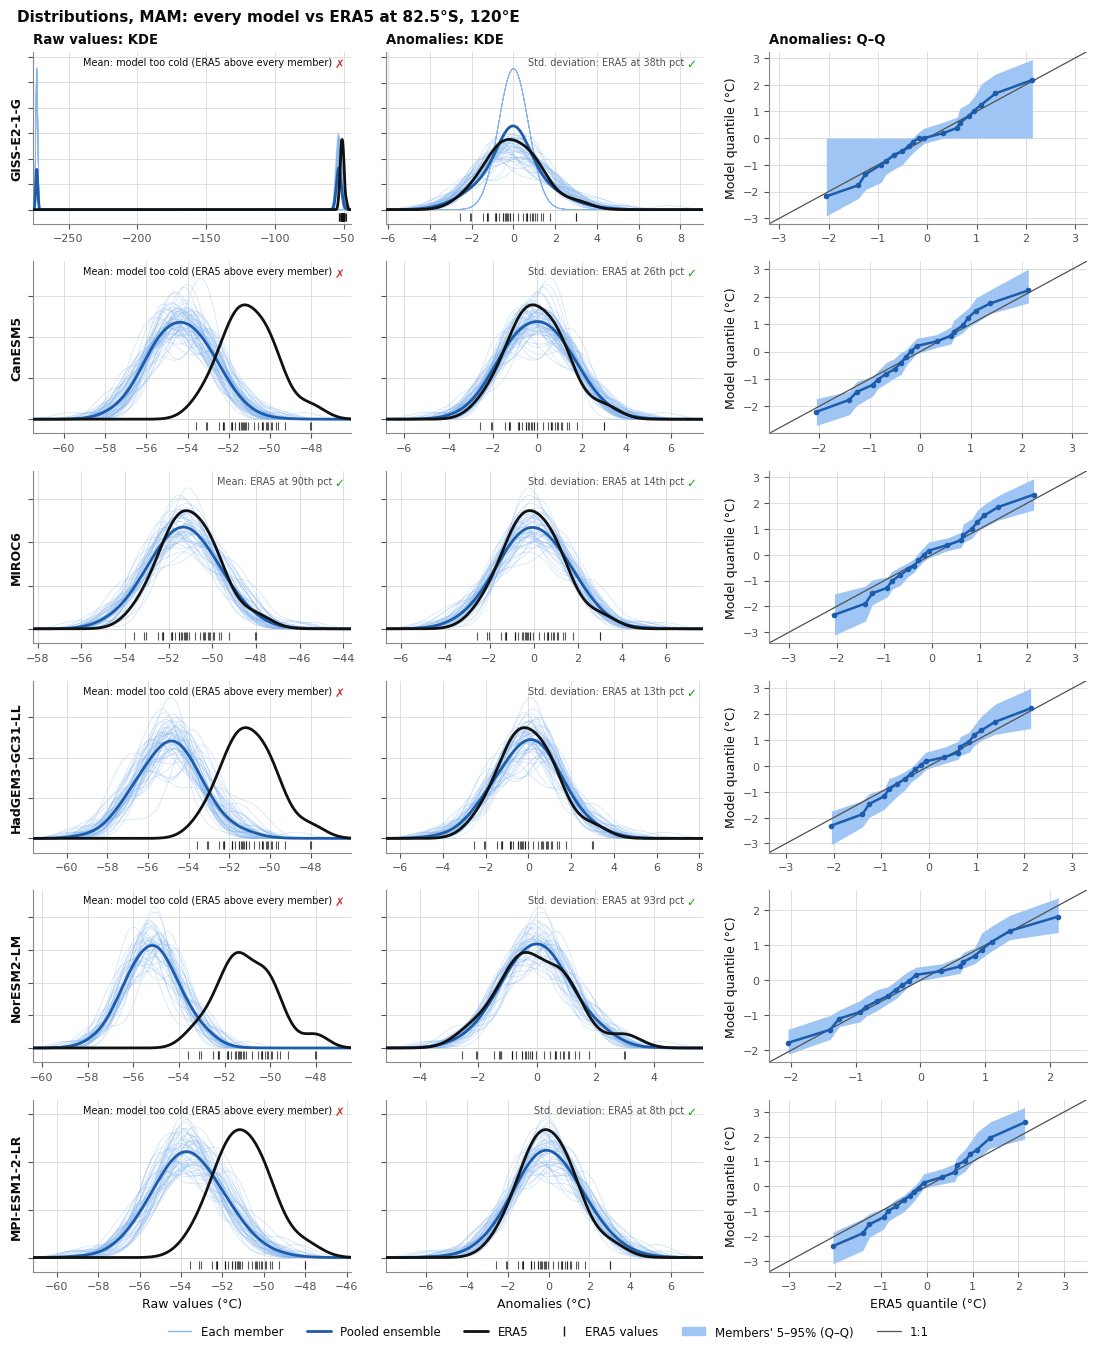

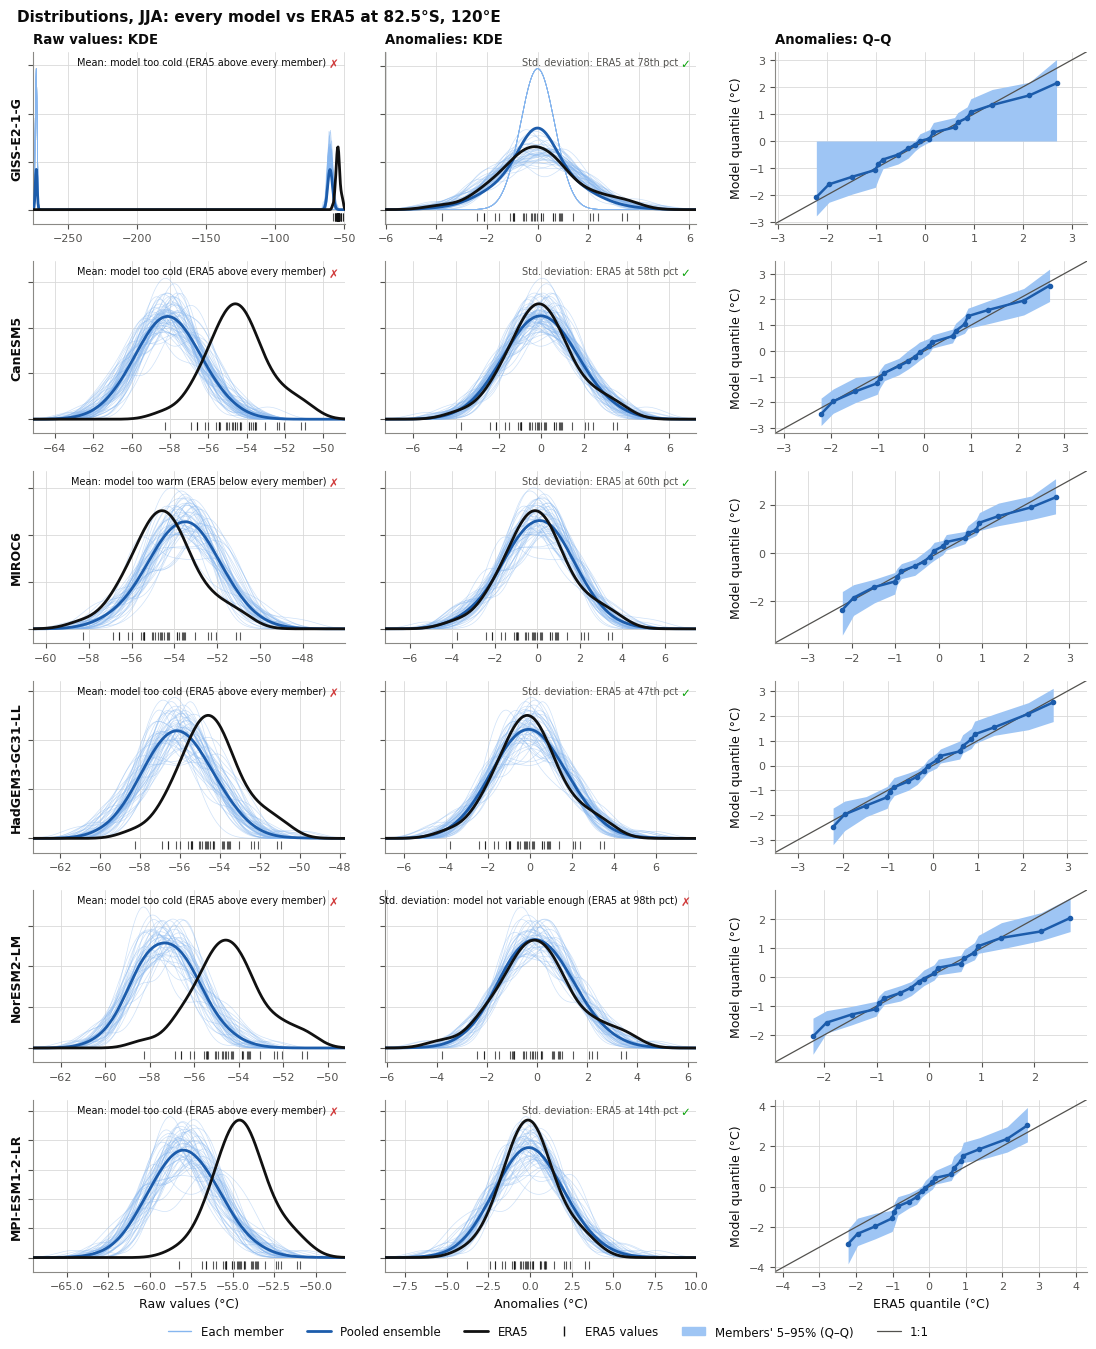

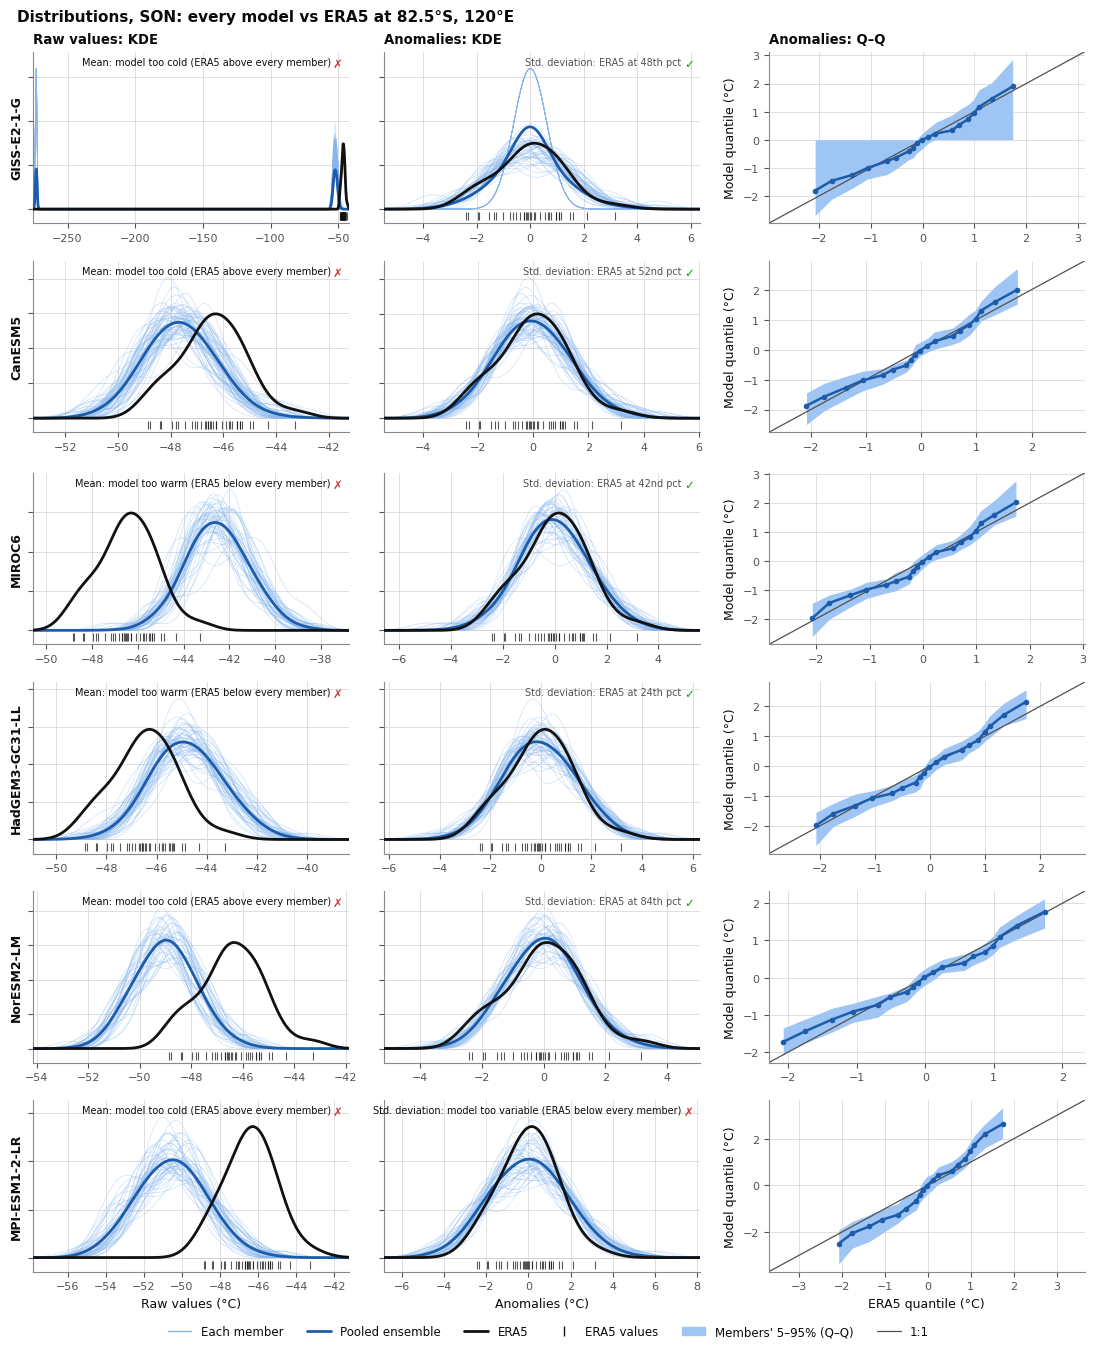

In [64]:
#(t): Every model (rows): the same three panels, one figure per season
distribution_models = list(all_distributions)
for season in SEASONS:
    fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(distribution_models), n_cols=3, n_legends=1,
                                                      panel_height=1.5, left_margin=1.4), layout='constrained')
    axes = fig.add_gridspec(len(distribution_models), 3).subplots(squeeze=False)
    for i, model in enumerate(distribution_models):
        evp.plot_kde(all_distributions[model]['raw'].sel(season=season), ax=axes[i, 0])
        evp.plot_kde(all_distributions[model]['anomaly'].sel(season=season), ax=axes[i, 1])
        evp.plot_qq(all_distributions[model]['anomaly'].sel(season=season), ax=axes[i, 2])
        row_moments_ds = moment_test_tree[model]['historical'].to_dataset().sel(season=season)
        for ax, treatment in zip(axes[i, :2], ['raw', 'anomaly']):
            ok, message = evp.verdict(row_moments_ds, evp.KDE_STATISTIC[treatment])
            evp.status_line(ax, 0.98, 0.97, ok, message, ha='right', fontsize=7)
            ax.tick_params(axis='y', labelleft=False)
        axes[i, 0].set_ylabel(model, fontweight='bold')
        axes[i, 2].set_ylabel(f'Model quantile ({VARIABLE.units})')

    axes[0, 0].set_title(f"{ev.TREATMENTS['raw']}: KDE", loc='left')
    axes[0, 1].set_title(f"{ev.TREATMENTS['anomaly']}: KDE", loc='left')
    axes[0, 2].set_title(f"{ev.TREATMENTS['anomaly']}: Q–Q", loc='left')
    axes[-1, 0].set_xlabel(f"{ev.TREATMENTS['raw']} ({VARIABLE.units})")
    axes[-1, 1].set_xlabel(f"{ev.TREATMENTS['anomaly']} ({VARIABLE.units})")
    axes[-1, 2].set_xlabel(f'ERA5 quantile ({VARIABLE.units})')
    fig.legend(handles=evp.distribution_legend_handles(), loc='outside lower center', ncols=6, frameon=False)
    fig.suptitle(f'Distributions, {season}: every model vs ERA5 at {POINT_LABEL}', x=0.01, ha='left')

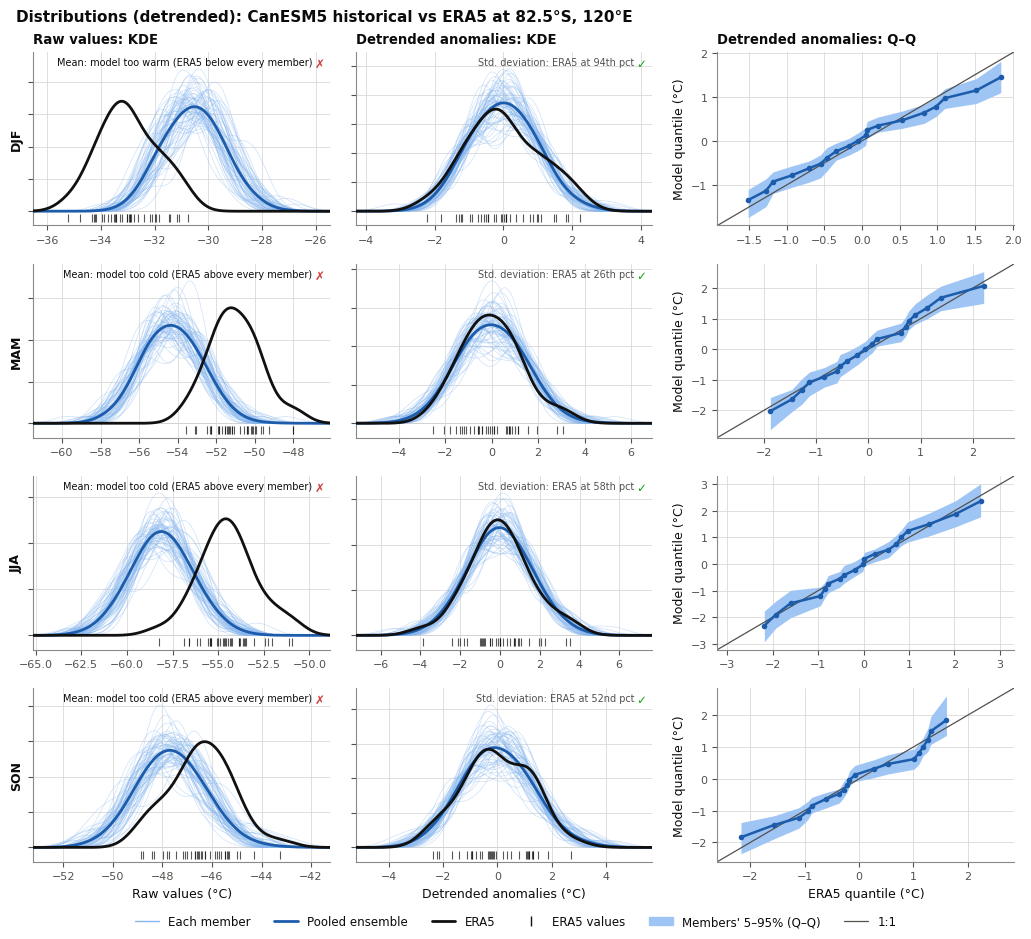

In [65]:
#(t): Detrended anomalies instead, to compare the noise alone: the raw values' KDEs, the detrended anomalies' KDEs and
#(t): Q-Q plot, seasons down
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=3, n_legends=1, panel_height=1.5),
                 layout='constrained')
axes = fig.add_gridspec(len(SEASONS), 3).subplots(squeeze=False)
for i, season in enumerate(SEASONS):
    evp.plot_kde(eval_distributions['raw'].sel(season=season), ax=axes[i, 0])
    evp.plot_kde(eval_distributions['detrended'].sel(season=season), ax=axes[i, 1])
    evp.plot_qq(eval_distributions['detrended'].sel(season=season), ax=axes[i, 2])
    for ax, treatment in zip(axes[i, :2], ['raw', 'detrended']):
        ok, message = evp.verdict(model_moments_ds.sel(season=season), evp.KDE_STATISTIC[treatment])
        evp.status_line(ax, 0.98, 0.97, ok, message, ha='right', fontsize=7)
        ax.tick_params(axis='y', labelleft=False)
    axes[i, 0].set_ylabel(season, fontweight='bold')
    axes[i, 2].set_ylabel(f'Model quantile ({VARIABLE.units})')

axes[0, 0].set_title(f"{ev.TREATMENTS['raw']}: KDE", loc='left')
axes[0, 1].set_title(f"{ev.TREATMENTS['detrended']}: KDE", loc='left')
axes[0, 2].set_title(f"{ev.TREATMENTS['detrended']}: Q–Q", loc='left')
axes[-1, 0].set_xlabel(f"{ev.TREATMENTS['raw']} ({VARIABLE.units})")
axes[-1, 1].set_xlabel(f"{ev.TREATMENTS['detrended']} ({VARIABLE.units})")
axes[-1, 2].set_xlabel(f'ERA5 quantile ({VARIABLE.units})')
fig.legend(handles=evp.distribution_legend_handles(), loc='outside lower center', ncols=6, frameon=False)
fig.suptitle(f'Distributions (detrended): {EXAMPLE_MODEL} historical vs ERA5 at {POINT_LABEL}', x=0.01, ha='left');

**What to look for**
- A raw-value KDE shifted from the ensemble is a mean-state bias. If the anomaly KDE then sits on top of the ensemble, the bias was the only problem.
- An anomaly KDE narrower or wider than the members' means the model has too much or too little variability. Check whether the std test (✓/✗) agrees.
- With ~35 values per season, a single ERA5 KDE is noisy. Judge it against the spread of the thin member curves, which have the same sample size, not against the smooth pooled curve.

## 3. Time Series: the Ensemble Plume

Blue bands are the ensemble's central 75% (12.5–87.5%, as in Suarez-Gutierrez et al., 2021), 5–95% and full range each year, with its median. ERA5 is black, with an orange ▲/▼ wherever it is above or below *every* member. If ERA5 were a member, that would happen 200 / (N + 1) % of the time (a few %), as noted in each panel. In the anomaly column, green outlines show the hist-nat ensemble for context.

In [66]:
#(t): EXAMPLE_MODEL's plume, raw values: the members' quantiles and range each year, and where ERA5 is
#(t): (ev.ensemble_plume)
eval_raw_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='raw')
eval_raw_plume_ds

<xarray.Dataset> Size: 11kB
Dimensions:           (season: 4, year: 35, quantile: 5)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 6kB -32.36 ... -45.28
    minimum           (year, season) float32 560B -33.47 -61.51 ... -56.39 -49.2
    maximum           (year, season) float32 560B -28.91 -55.62 ... -44.27
    obs               (year, season) float32 560B -32.97 -55.57 ... -43.27
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 1.0 1.0 0.0 ... 1.0 0.0 1.0
    central           (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [67]:
#(t): ... and anomalies
eval_anomaly_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='anomaly')
eval_anomaly_plume_ds

<xarray.Dataset> Size: 11kB
Dimensions:           (season: 4, year: 35, quantile: 5)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 6kB -1.897 ... 2.331
    minimum           (year, season) float32 560B -3.295 -3.451 ... -1.478
    maximum           (year, season) float32 560B 1.842 2.051 ... 3.859 3.305
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [68]:
#(t): The two along a treatment dim, on (treatment, quantile, year, season)
point_plume_ds = xr.concat([eval_raw_plume_ds, eval_anomaly_plume_ds], dim=xr.Variable('treatment', ['raw', 'anomaly']))
point_plume_ds

<xarray.Dataset> Size: 22kB
Dimensions:           (treatment: 2, quantile: 5, year: 35, season: 4)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
  * treatment         (treatment) <U7 56B 'raw' 'anomaly'
Data variables:
    quantiles         (treatment, quantile, year, season) float64 11kB -32.36...
    minimum           (treatment, year, season) float32 1kB -33.47 ... -1.478
    maximum           (treatment, year, season) float32 1kB -28.91 ... 3.305
    obs               (treatment, year, season) float32 1kB -32.97 ... 3.176
    below             (treatment, year, season) float64 2kB 0.0 0.0 ... 0.0 0.0
    above             (treatment, year, season) float64 2kB 0.0 1.0 ... 0.0 0.0
    central           (treatment, year, season) float64 2kB 0.0 0.0 ... 0.0 0.0
    n_members         (treatment) int64 16B 65 65
    expected_outside  (treatment) float64 16B 3.03 3.03
Attributes: (1)

In [69]:
#(t): The historical ensemble-mean climatology at the point: the mean over members and years, per season
point_hist_climatology_da = eval_members_da.mean(['member', 'year'])
point_hist_climatology_da

<xarray.DataArray 'tas' (season: 4)> Size: 16B
-30.56 -58.09 -54.3 -47.64
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lat      float64 8B -82.5
    lon      float64 8B 120.0

In [70]:
#(t): ERA5's climatology at the point, over the same years and missing-data mask
point_era5_climatology_da = eval_era5_da.mean('year')
point_era5_climatology_da

<xarray.DataArray 'tas' (season: 4)> Size: 16B
-32.97 -54.47 -51.02 -46.45
Coordinates:
  * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
    lon      float64 8B 120.0
    lat      float64 8B -82.5

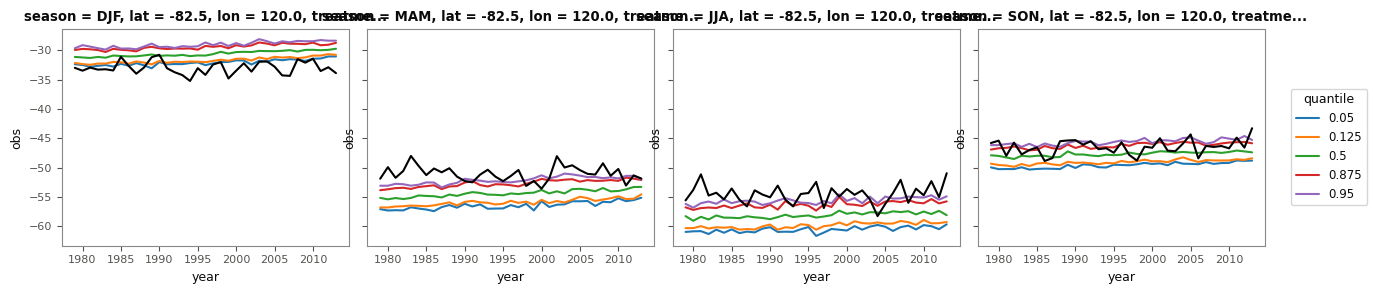

In [71]:
#(t): Quick look: the raw-value plume's quantiles (colours) and ERA5 (black), one panel per season
point_raw_plume_ds = point_plume_ds.sel(treatment='raw', season=SEASONS)
fg = point_raw_plume_ds['quantiles'].plot(x='year', hue='quantile', col='season')
for ax, season in zip(fg.axs.flat, SEASONS):
    point_raw_plume_ds['obs'].sel(season=season).plot(ax=ax, color='k')

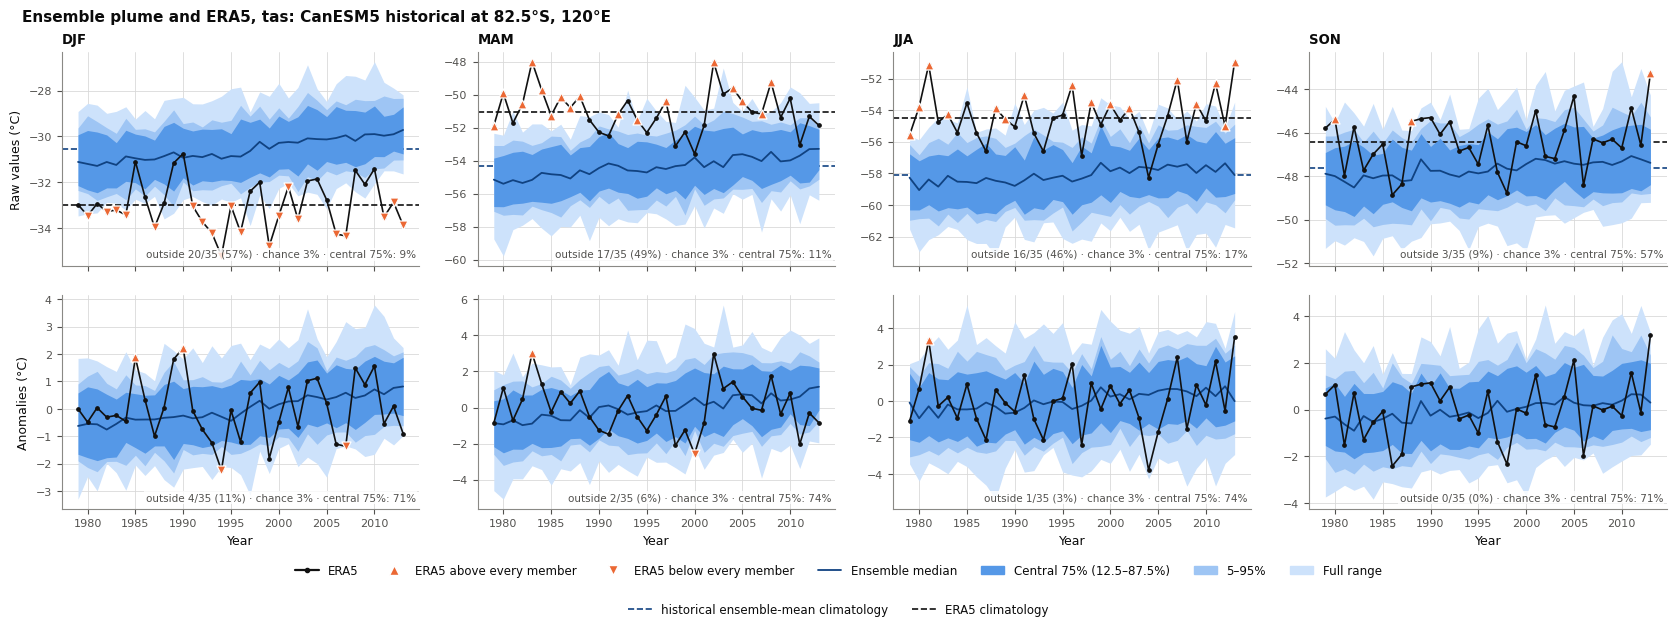

In [72]:
#(t): Raw values and anomalies (rows), seasons (columns): EXAMPLE_MODEL's plume and ERA5. Dashed: the two climatologies,
#(t): on the
#(t): raw values
plume_treatments = list(point_plume_ds['treatment'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(plume_treatments), n_cols=len(SEASONS), n_legends=2,
                                                  panel_width=3.6, panel_height=1.8), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(len(plume_treatments), len(SEASONS)).subplots(sharex=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for i, treatment in enumerate(plume_treatments):
    for j, season in enumerate(SEASONS):
        evp.plot_plume(point_plume_ds.sel(treatment=treatment, season=season), ax=axes[i, j])
    axes[i, 0].set_ylabel(f'{ev.TREATMENTS[treatment]} ({VARIABLE.units})')
for ax, season in zip(axes[0], SEASONS):
    ax.axhline(point_hist_climatology_da.sel(season=season), color=evp.ENSEMBLE['median'], lw=1.2, ls='--')
    ax.axhline(point_era5_climatology_da.sel(season=season), color=evp.ERA5_COLOR, lw=1.2, ls='--')
    ax.set_title(season, loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Year')
legend_axes[0].legend(handles=evp.plume_legend_handles(), loc='center', ncols=7, frameon=False)
legend_axes[1].legend(handles=[
    Line2D([], [], color=evp.ENSEMBLE['median'], lw=1.2, ls='--', label='historical ensemble-mean climatology'),
    Line2D([], [], color=evp.ERA5_COLOR, lw=1.2, ls='--', label='ERA5 climatology'),
], loc='center', ncols=2, frameon=False)
fig.suptitle(f'Ensemble plume and ERA5, {VARIABLE.name}: {EXAMPLE_MODEL} historical at {POINT_LABEL}', x=0.01,
             ha='left');

In [73]:
#(t): The plume: 0-100% in 5% steps, drawn as nested bands from the widest (0-100%) in
PLUME_QUANTILES = np.round(np.linspace(0, 1, 21), 2)
PLUME_PAIRS = np.column_stack([PLUME_QUANTILES[:10], PLUME_QUANTILES[::-1][:10]])
PLUME_PAIRS

array([[0.  , 1.  ],
       [0.05, 0.95],
       [0.1 , 0.9 ],
       [0.15, 0.85],
       [0.2 , 0.8 ],
       [0.25, 0.75],
       [0.3 , 0.7 ],
       [0.35, 0.65],
       [0.4 , 0.6 ],
       [0.45, 0.55]])

In [74]:
#(t): EXAMPLE_MODEL's plume and ERA5 at the point, raw values, on (quantile, year, season), at PLUME_QUANTILES
point_raw_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='raw', quantiles=PLUME_QUANTILES)
point_raw_plume_ds

<xarray.Dataset> Size: 29kB
Dimensions:           (season: 4, year: 35, quantile: 21)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 24kB -33.47 ... -44.27
    minimum           (year, season) float32 560B -33.47 -61.51 ... -56.39 -49.2
    maximum           (year, season) float32 560B -28.91 -55.62 ... -44.27
    obs               (year, season) float32 560B -32.97 -55.57 ... -43.27
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 1.0 1.0 0.0 ... 1.0 0.0 1.0
    central           (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [75]:
#(t): The same for anomalies: each member and ERA5 minus its own mean in each season
point_anomaly_plume_ds = ev.ensemble_plume(eval_members_da, eval_era5_da, treatment='anomaly', quantiles=PLUME_QUANTILES)
point_anomaly_plume_ds

<xarray.Dataset> Size: 29kB
Dimensions:           (season: 4, year: 35, quantile: 21)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 24kB -3.295 ... 3.305
    minimum           (year, season) float32 560B -3.295 -3.451 ... -1.478
    maximum           (year, season) float32 560B 1.842 2.051 ... 3.859 3.305
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [76]:
#(t): Each season's middle month, as a fraction of a year
#(c): DJF is labelled by its December's year, so its middle month (January) is in the next year
SEASON_MIDDLE = xr.DataArray([12.5, 3.5, 6.5, 9.5], coords={'season': ['DJF', 'MAM', 'JJA', 'SON']}) / 12


def seasons_in_time(obj):
    """Put (year, season) on one time axis, in decimal years at each season's middle month.

    year and season stay as coordinates along time, so a seasonal climatology can be
    looked up at every time step with .sel(season=...), like the old day-of-year lookup.

    Args:
        obj (xr.Dataset | xr.DataArray): Data on (year, season, ...).

    Returns:
        The same on (time, ...), time in decimal years, sorted; DJF 1980 is at 1981.04 (January 1981).
    """
    decimal_year_da = obj['year'] + SEASON_MIDDLE.sel(season=obj['season'])
    with_time = obj.assign_coords(time=decimal_year_da)
    stacked = with_time.stack(sample=['year', 'season'])
    stacked = stacked.reset_index('sample')        # year and season become plain coordinates
    stacked = stacked.swap_dims(sample='time')
    return stacked.sortby('time')

In [77]:
#(t): The raw-value plume on one time axis
point_raw_plume_time_ds = seasons_in_time(point_raw_plume_ds)
point_raw_plume_time_ds

<xarray.Dataset> Size: 33kB
Dimensions:           (quantile: 21, time: 140)
Coordinates:
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
  * time              (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03
    year              (time) int64 1kB 1979 1979 1979 1979 ... 2013 2013 2013
    season            (time) <U3 2kB 'MAM' 'JJA' 'SON' ... 'JJA' 'SON' 'DJF'
Data variables:
    quantiles         (quantile, time) float64 24kB -58.74 -61.51 ... -28.18
    minimum           (time) float32 560B -58.74 -61.51 -51.31 ... -49.2 -31.63
    maximum           (time) float32 560B -52.34 -55.62 -44.79 ... -44.27 -28.18
    obs               (time) float32 560B -51.88 -55.57 -45.79 ... -43.27 -33.87
    below             (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 1.0
    above             (time) float64 1kB 1.0 1.0 0.0 0.0 1.0 ... 0.0 1.0 1.0 0.0
    central           (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [78]:
#(t): Check: the times are in order, one per season, and DJF 1980 sits at January 1981 (1981 + 0.5 / 12 = 1981.042)
raw_times_index = point_raw_plume_time_ds.indexes['time']
djf_1980_arr = raw_times_index[(point_raw_plume_time_ds['season'].values == 'DJF')
                               & (point_raw_plume_time_ds['year'].values == 1980)].values
(raw_times_index.is_monotonic_increasing, len(raw_times_index) == point_raw_plume_ds.sizes['year'] * 4,
 djf_1980_arr.round(3))

(True, True, array([1981.042]))

In [79]:
#(t): The anomaly plume on one time axis
point_anomaly_plume_time_ds = seasons_in_time(point_anomaly_plume_ds)
point_anomaly_plume_time_ds

<xarray.Dataset> Size: 33kB
Dimensions:           (quantile: 21, time: 140)
Coordinates:
  * quantile          (quantile) float64 168B 0.0 0.05 0.1 0.15 ... 0.9 0.95 1.0
    lat               float64 8B -82.5
    lon               float64 8B 120.0
  * time              (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03
    year              (time) int64 1kB 1979 1979 1979 1979 ... 2013 2013 2013
    season            (time) <U3 2kB 'MAM' 'JJA' 'SON' ... 'JJA' 'SON' 'DJF'
Data variables:
    quantiles         (quantile, time) float64 24kB -4.601 -3.451 ... 2.238
    minimum           (time) float32 560B -4.601 -3.451 ... -1.478 -0.9785
    maximum           (time) float32 560B 2.069 2.051 2.603 ... 4.91 3.305 2.238
    obs               (time) float32 560B -0.8627 -1.103 ... 3.176 -0.9004
    below             (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    above             (time) float64 1kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    central           (time) float64 1kB 1.0 1.0 1.0 1.0 0.0 ... 0.0 0.0 0.0 0.0
    n_members         int64 8B 65
    expected_outside  float64 8B 3.03
Attributes: (1)

In [80]:
#(t): The historical climatology at every time step, looked up by season
point_hist_climatology_time_da = point_hist_climatology_da.sel(season=point_raw_plume_time_ds['season'])
point_hist_climatology_time_da

<xarray.DataArray 'tas' (time: 140)> Size: 560B
-54.3 -58.09 -47.64 -30.56 -54.3 -58.09 ... -30.56 -54.3 -58.09 -47.64 -30.56
Coordinates:
    season   (time) object 1kB 'MAM' 'JJA' 'SON' 'DJF' ... 'JJA' 'SON' 'DJF'
    lat      float64 8B -82.5
    lon      float64 8B 120.0
  * time     (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03 2.014e+03
    year     (time) int64 1kB 1979 1979 1979 1979 1980 ... 2013 2013 2013 2013

In [81]:
#(t): ERA5's climatology at every time step, looked up by season
point_era5_climatology_time_da = point_era5_climatology_da.sel(season=point_raw_plume_time_ds['season'])
point_era5_climatology_time_da

<xarray.DataArray 'tas' (time: 140)> Size: 560B
-51.02 -54.47 -46.45 -32.97 -51.02 -54.47 ... -32.97 -51.02 -54.47 -46.45 -32.97
Coordinates:
    season   (time) object 1kB 'MAM' 'JJA' 'SON' 'DJF' ... 'JJA' 'SON' 'DJF'
    lon      float64 8B 120.0
    lat      float64 8B -82.5
  * time     (time) float64 1kB 1.979e+03 1.98e+03 ... 2.014e+03 2.014e+03
    year     (time) int64 1kB 1979 1979 1979 1979 1980 ... 2013 2013 2013 2013

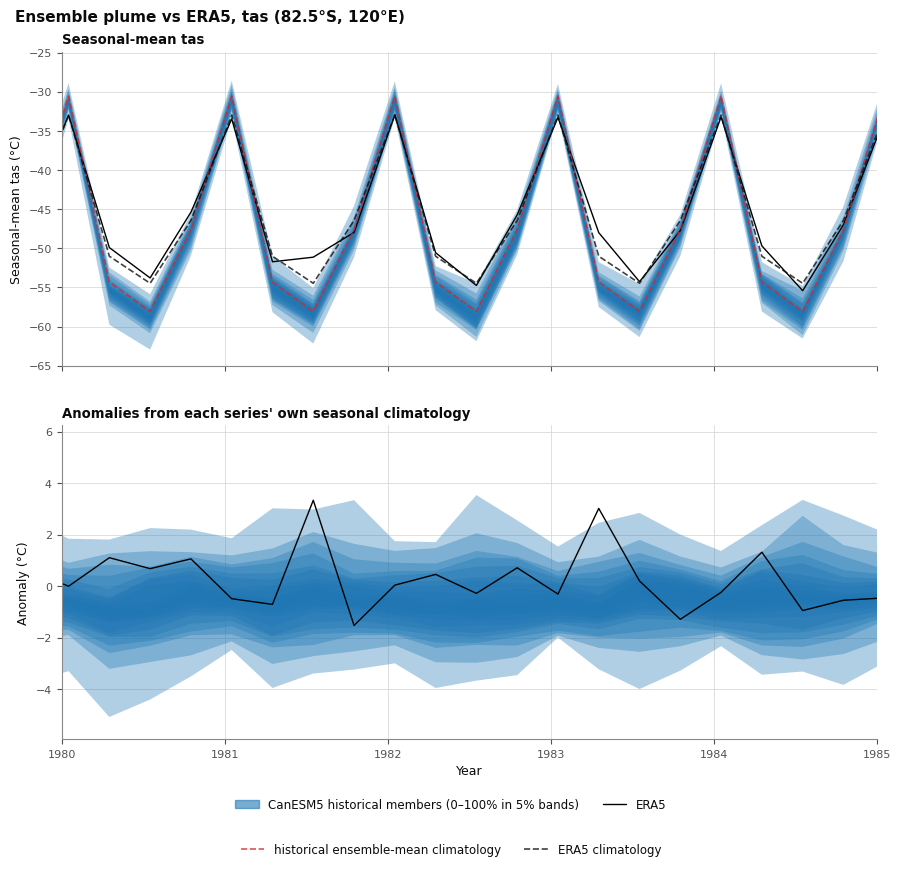

In [82]:
#(t): EXAMPLE_MODEL's plume (0-100% in 5% bands, PLUME_PAIRS, each band drawn over the last) and ERA5, on one time axis:
#(t): the
#(t): raw values with the two climatologies (top), and the anomalies (bottom); 1980-1985 shown
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=2, n_cols=1, n_legends=2, panel_width=8.0, panel_height=3.0),
                 layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(2, 1).subplots(sharex=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for ax, plume_time_ds in zip(axes[:, 0], [point_raw_plume_time_ds, point_anomaly_plume_time_ds]):
    charts.plot_quantile_bands(plume_time_ds['quantiles'], PLUME_PAIRS, 'time', ax=ax, color='C0', alpha=0.35)
    charts.plot_lines(plume_time_ds['obs'], 'time', ax=ax, color='k', linewidth=1)
charts.plot_lines(point_hist_climatology_time_da, 'time', ax=axes[0, 0], color='C3', linewidth=1.2, linestyle='--',
                  alpha=0.8)
charts.plot_lines(point_era5_climatology_time_da, 'time', ax=axes[0, 0], color=evp.ERA5_COLOR, linewidth=1.2,
                  linestyle='--', alpha=0.8)

axes[0, 0].set_title(f'Seasonal-mean {VARIABLE.name}', loc='left')
axes[0, 0].set_ylabel(f'Seasonal-mean {VARIABLE.name} ({VARIABLE.units})')
axes[1, 0].set_title("Anomalies from each series' own seasonal climatology", loc='left')
axes[1, 0].set_ylabel(f'Anomaly ({VARIABLE.units})')
axes[1, 0].set_xlabel('Year')
#(c): The x axis is shared: its range set once
axes[0, 0].set_xlim(1980, 1985)
legend_axes[0].legend(handles=[Patch(color='C0', alpha=0.6,
                                     label=f'{EXAMPLE_MODEL} historical members (0–100% in 5% bands)'),
                               Line2D([], [], color='k', lw=1, label='ERA5')], loc='center', ncols=2, frameon=False)
legend_axes[1].legend(handles=[
    Line2D([], [], color='C3', lw=1.2, ls='--', alpha=0.8, label='historical ensemble-mean climatology'),
    Line2D([], [], color=evp.ERA5_COLOR, lw=1.2, ls='--', alpha=0.8, label='ERA5 climatology'),
], loc='center', ncols=2, frameon=False)
fig.suptitle(f'Ensemble plume vs ERA5, {VARIABLE.name} ({POINT_LABEL})', x=0.01, ha='left');

In [83]:
#(t): hist-nat's anomaly plume at the point, as context: ERA5 should follow historical, not hist-nat
histnat_plume_ds = ev.ensemble_plume(histnat_point_tree[EXAMPLE_MODEL]['hist-nat']['tas'], era5_point_da,
                                     treatment='anomaly')
histnat_plume_ds

<xarray.Dataset> Size: 11kB
Dimensions:           (season: 4, year: 35, quantile: 5)
Coordinates:
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season) float64 6kB -1.653 ... 1.459
    minimum           (year, season) float32 560B -2.543 -2.355 ... -2.982
    maximum           (year, season) float32 560B 1.735 3.383 ... 2.685 2.784
    obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
    below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 1.0 0.0 1.0
    central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 1.0 0.0
    n_members         int64 8B 50
    expected_outside  float64 8B 3.922
Attributes: (1)

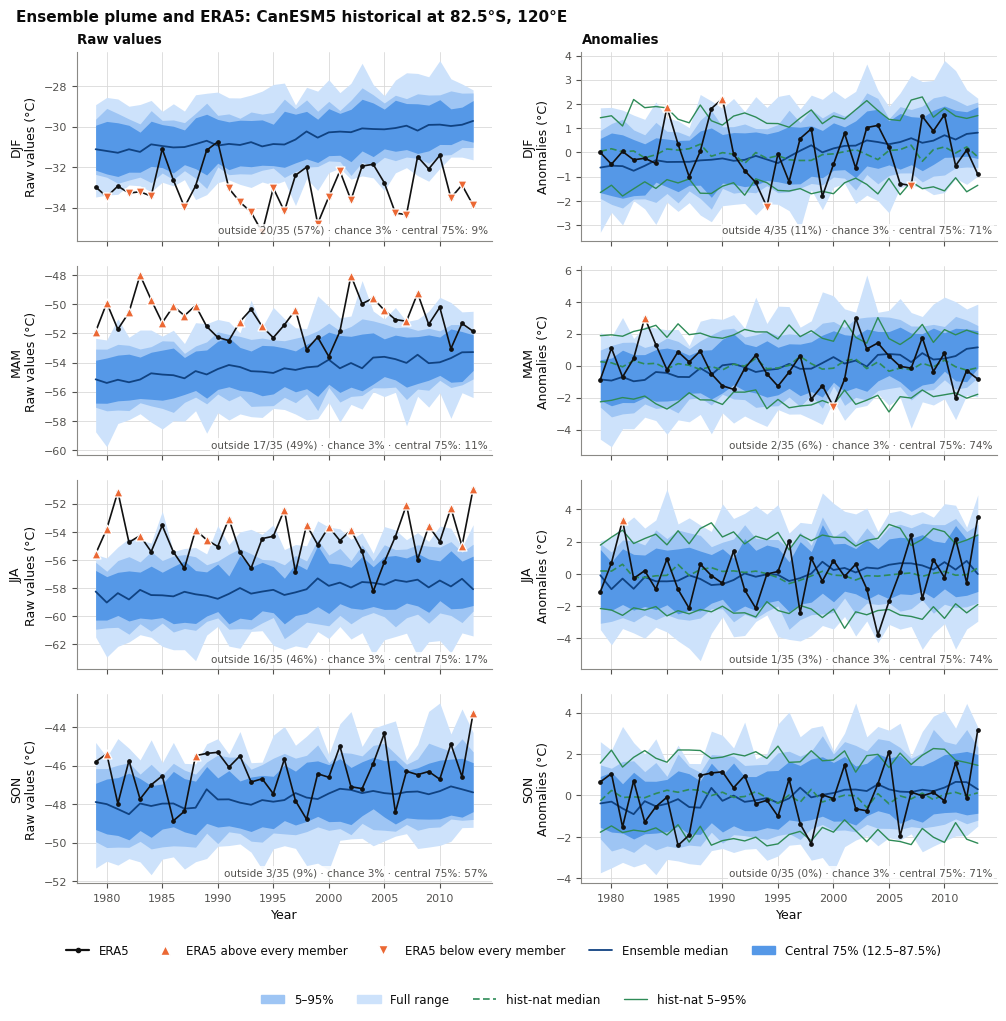

In [84]:
#(t): One model: seasons (rows) × raw values and anomalies (columns), with hist-nat (green) for context on the
#(t): anomalies, which is what it has
plume_treatments = list(point_plume_ds['treatment'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(SEASONS), n_cols=len(plume_treatments), n_legends=2,
                                                  panel_width=4.3, panel_height=1.6), layout='constrained')
#(c): The panels, then a row for each legend (the layout gives each the room it needs)
grid = fig.add_gridspec(3, 1, height_ratios=[1, 0.01, 0.01])
axes = grid[0].subgridspec(len(SEASONS), len(plume_treatments)).subplots(sharex=True, squeeze=False)
legend_axes = [fig.add_subplot(grid[row]) for row in (1, 2)]
for legend_ax in legend_axes:
    legend_ax.axis('off')
for i, season in enumerate(SEASONS):
    for j, treatment in enumerate(plume_treatments):
        context_ds = histnat_plume_ds.sel(season=season) if treatment == 'anomaly' else None
        evp.plot_plume(point_plume_ds.sel(season=season, treatment=treatment), ax=axes[i, j], context=context_ds)
        axes[i, j].set_ylabel(f'{season}\n{ev.TREATMENTS[treatment]} ({VARIABLE.units})')
for ax, treatment in zip(axes[0], plume_treatments):
    ax.set_title(ev.TREATMENTS[treatment], loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Year')
plume_handles = evp.plume_legend_handles(context=True)
legend_axes[0].legend(handles=plume_handles[:5], loc='center', ncols=5, frameon=False)
legend_axes[1].legend(handles=plume_handles[5:], loc='center', ncols=4, frameon=False)
fig.suptitle(f'Ensemble plume and ERA5: {EXAMPLE_MODEL} historical at {POINT_LABEL}', x=0.01, ha='left');

In [85]:
#(t): Every model's anomaly plume (ev.ensemble_plume of each model's members, against ERA5)
all_plumes_tree = xr.DataTree.from_dict({
    node.path: ev.ensemble_plume(node['tas'], era5_point_da, treatment='anomaly') for node in historical_point_tree.leaves
})
all_plumes_tree

<xarray.DataTree>
Group: /
├── Group: /GISS-E2-1-G
│   └── Group: /GISS-E2-1-G/historical
│           Dimensions:           (year: 35, season: 4, quantile: 5)
│           Coordinates:
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
│               lat               float64 8B -82.5
│               lon               float64 8B 120.0
│           Data variables:
│               quantiles         (quantile, year, season) float64 6kB -1.918 ... 2.135
│               minimum           (year, season) float32 560B -3.12 -3.93 ... -4.077 -2.463
│               maximum           (year, season) float32 560B 2.761 2.62 ... 7.445 3.691
│               obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
│               below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               central           (year, season) float64 1kB 1.0 1.0 1.0 0.0 ... 0.0 0.0 0.0
│               n_members         int64 8B 63
│               expected_outside  float64 8B 3.125
│           Attributes: (1)
├── Group: /CanESM5
│   └── Group: /CanESM5/historical
│           Dimensions:           (season: 4, year: 35, quantile: 5)
│           Coordinates:
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│             * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
│               lat               float64 8B -82.5
│               lon               float64 8B 120.0
│           Data variables:
│               quantiles         (quantile, year, season) float64 6kB -1.897 ... 2.331
│               minimum           (year, season) float32 560B -3.295 -3.451 ... -1.478
│               maximum           (year, season) float32 560B 1.842 2.051 ... 3.859 3.305
│               obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
│               below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               central           (year, season) float64 1kB 1.0 1.0 1.0 1.0 ... 0.0 0.0 0.0
│               n_members         int64 8B 65
│               expected_outside  float64 8B 3.03
│           Attributes: (1)
├── Group: /MIROC6
│   └── Group: /MIROC6/historical
│           Dimensions:           (year: 35, season: 4, quantile: 5)
│           Coordinates:
│             * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
│             * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
│               lat               float64 8B -82.5
│               lon               float64 8B 120.0
│           Data variables:
│               quantiles         (quantile, year, season) float64 6kB -1.231 ... 1.73
│               minimum           (year, season) float32 560B -2.015 -4.351 ... -3.384 -3.1
│               maximum           (year, season) float32 560B 2.362 2.909 ... 5.772 2.92
│               obs               (year, season) float32 560B -0.0005684 -1.103 ... 3.176
│               below             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
│               above             (year, season) float64 1kB 0.0 0.0 0.0 0.0 ... 1.0 0.0 1.0
│               central           (year, season) float64 1kB 1.0 1.0 1.0 0.0 ... 0.0 1.0 0.0
│               n_members         int64 8B 50
│               expected_outside  float64 8B 3.922
│           Attributes: (1)
├── Group: /HadGEM3-GC31-LL
│   └── Group: /HadGEM3-GC31-LL/historical
│           Dimensio

In [86]:
#(t): Without the members, so they fit side by side on (model, quantile, year, season)
all_plumes_ds = tree_to_dataset(all_plumes_tree, dims=['model', 'experiment'])
all_plumes_ds = all_plumes_ds.sel(experiment='historical', drop=True)
all_plumes_ds

<xarray.Dataset> Size: 64kB
Dimensions:           (model: 6, quantile: 5, year: 35, season: 4)
Coordinates:
  * model             (model) object 48B 'CanESM5' ... 'NorESM2-LM'
  * year              (year) int64 280B 1979 1980 1981 1982 ... 2011 2012 2013
  * season            (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * quantile          (quantile) float64 40B 0.05 0.125 0.5 0.875 0.95
    lat               float64 8B -82.5
    lon               float64 8B 120.0
Data variables:
    quantiles         (quantile, year, season, model) float64 34kB -1.897 ......
    minimum           (year, season, model) float32 3kB -3.295 -3.12 ... -2.351
    maximum           (year, season, model) float32 3kB 1.842 2.761 ... 2.629
    obs               (year, season, model) float32 3kB -0.0005684 ... 3.176
    below             (year, season, model) float64 7kB 0.0 0.0 0.0 ... 0.0 0.0
    above             (year, season, model) float64 7kB 0.0 0.0 0.0 ... 0.0 1.0
    central           (year, season, model) float64 7kB 1.0 1.0 1.0 ... 0.0 0.0
    n_members         (model) int64 48B 65 63 55 50 51 43
    expected_outside  (model) float64 48B 3.03 3.125 3.571 3.922 3.846 4.545
Attributes: (1)

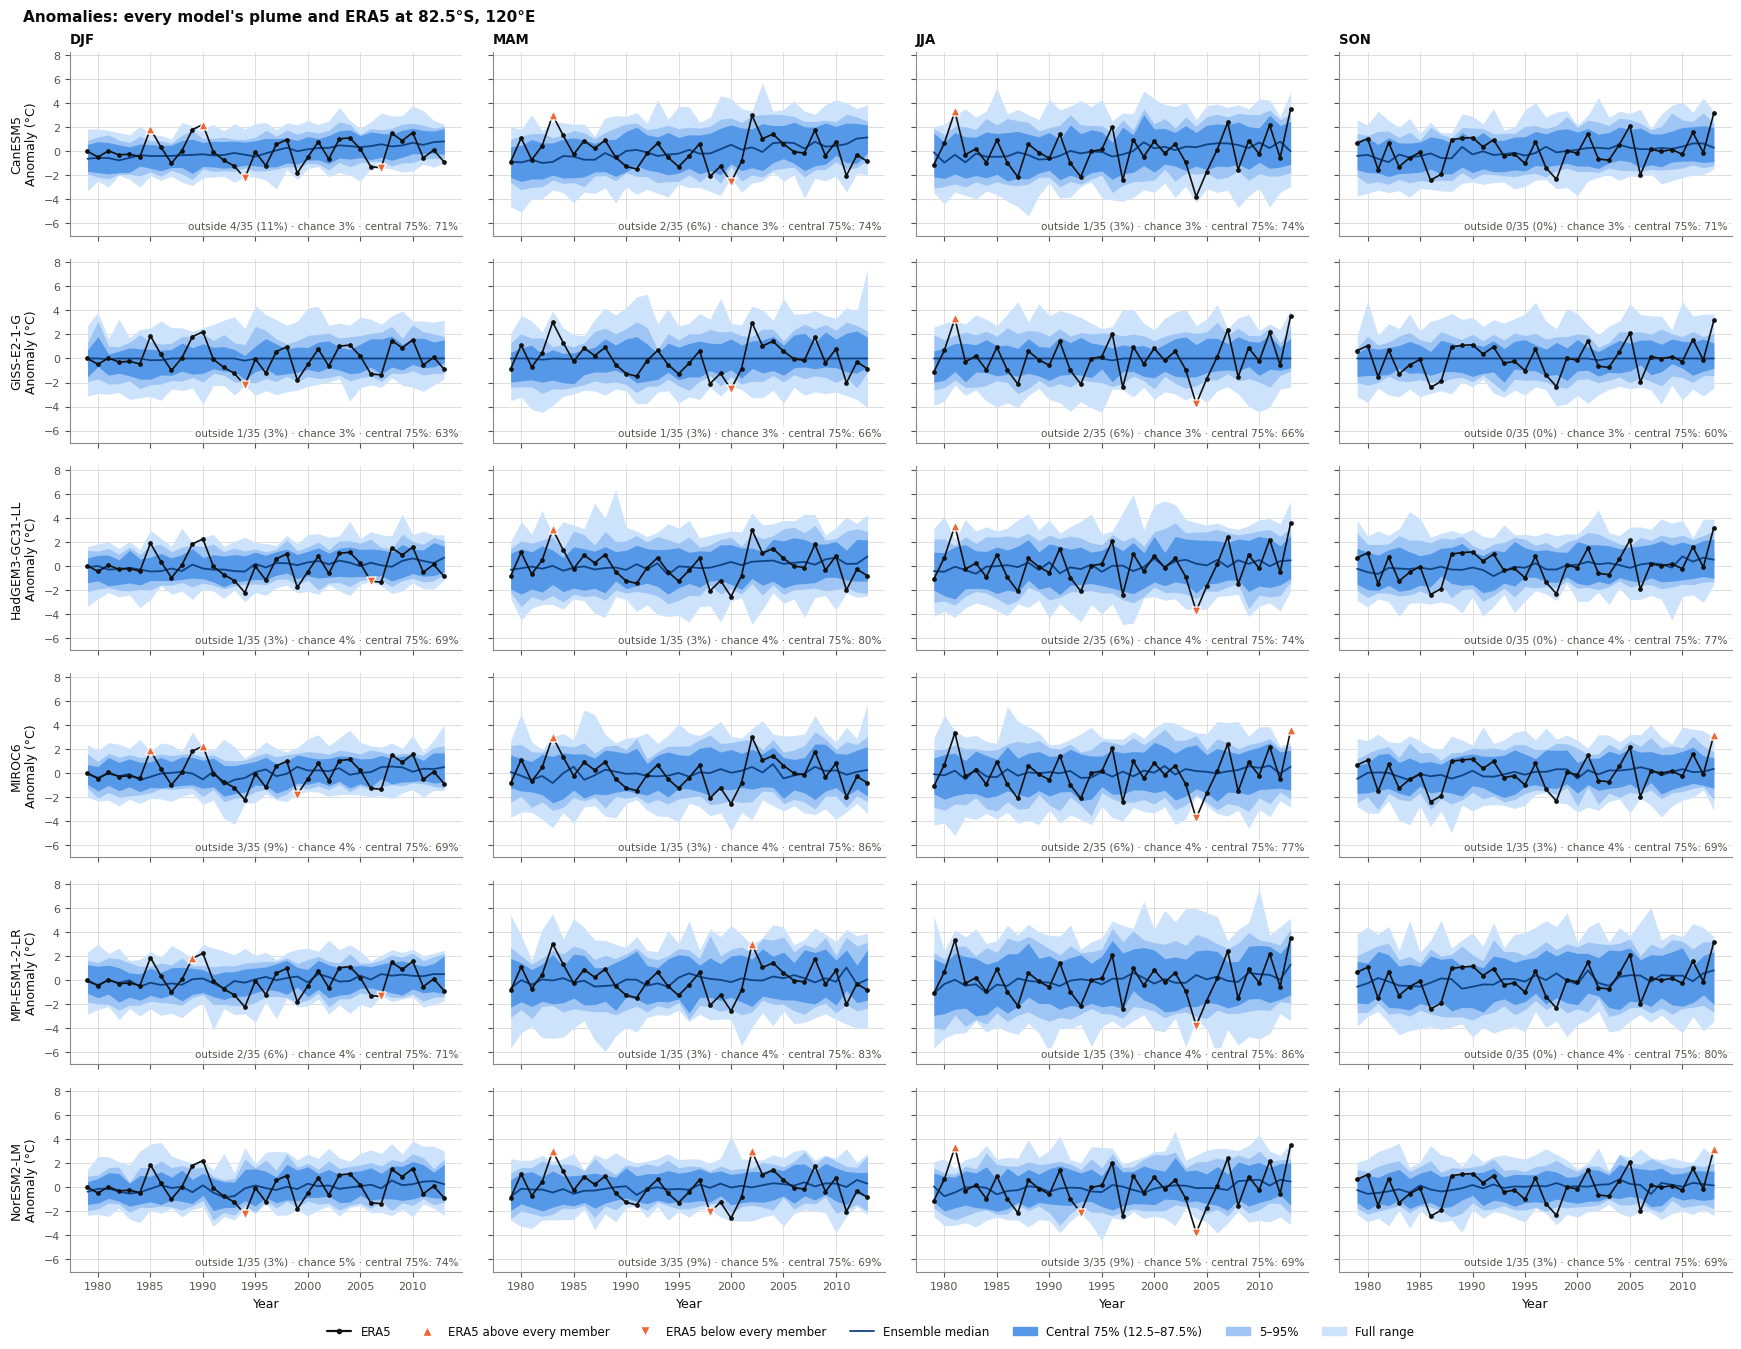

In [87]:
#(t): Anomalies: every model's plume (rows) and ERA5, seasons across, on one y scale
plume_models = list(all_plumes_ds['model'].values)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=len(plume_models), n_cols=len(SEASONS), n_legends=1,
                                                  panel_width=3.6, panel_height=1.5, left_margin=1.4),
                 layout='constrained')
axes = fig.add_gridspec(len(plume_models), len(SEASONS)).subplots(sharex=True, sharey=True, squeeze=False)
for i, model in enumerate(plume_models):
    for j, season in enumerate(SEASONS):
        evp.plot_plume(all_plumes_ds.sel(model=model, season=season), ax=axes[i, j])
    axes[i, 0].set_ylabel(f'{model}\nAnomaly ({VARIABLE.units})')
for ax, season in zip(axes[0], SEASONS):
    ax.set_title(season, loc='left')
for ax in axes[-1]:
    ax.set_xlabel('Year')
fig.legend(handles=evp.plume_legend_handles(), loc='outside lower center', ncols=7, frameon=False)
fig.suptitle(f"Anomalies: every model's plume and ERA5 at {POINT_LABEL}", x=0.01, ha='left');

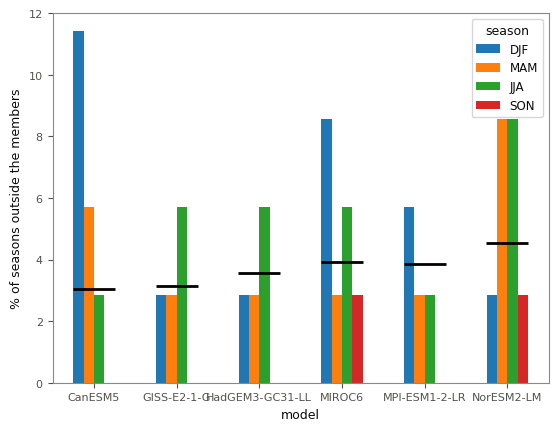

In [88]:
#(t): % of seasons with ERA5 outside each model's range (bars), against chance, 200 / (N + 1) % (black)
outside_ds = ev.outside_frequency(all_plumes_ds)
outside_df = outside_ds['outside'].sel(season=SEASONS).transpose('model', 'season').to_pandas()
ax = outside_df.plot.bar(rot=0, ylabel='% of seasons outside the members')
ax.plot(range(len(outside_df)), outside_ds['expected_outside'].to_pandas().values, 'k_', ms=30, mew=2);

**What to look for**
- Raw values outside the plume in most years, with anomalies inside it: a mean-state bias only.
- Anomalies outside the plume *at both extremes* more often than chance: too little noise, or a signal problem (which one is settled in plot_01b's section 5).
- ERA5 drifting from one edge of the anomaly plume towards the other through the record: the trend differs (the signal).